# CS156 Session 4 — Trees 1: Classification by Partition

In this session, I explored how decision trees classify observations by repeatedly dividing the feature space. I first examined the data visually, then used Gini impurity to calculate the best root split. Finally, I repeated the same process for each child node to build the second level of the tree.

The main idea is that a useful split creates groups that contain mostly one class. Gini impurity gives us a numerical way to measure this; lower impurity means the classes are better separated.

# Question 1 — Why Can Decision Trees Be Unstable?

The reading showed that small changes to the training data can produce very different decision trees. This happens because tree construction is sequential; changing an early split also changes which observations reach every later node.

I asked an LLM to explain this idea and then compared its response with the reading.

### Critique 1

The LLM wrote:

> "Perturb the data → tree changes dramatically → high variance/instability → potentially learns training-specific noise → overfitting."

This is slightly oversimplified. The reading describes high variance from perturbations and excessive tree depth as related problems that can both hurt generalization; instability does not automatically mean that the tree is overfitting.

### Critique 2

The LLM wrote:

> "A tree can be structurally unstable without every prediction being unstable."

This is possible, but the reading does not test this directly. It shows that the tree structures change after perturbations, but it does not compare whether the final predictions remain similar.

### Critique 3

The LLM also discussed how decision trees approximate diagonal boundaries using many horizontal and vertical splits.

This was useful, but it goes beyond the reading. The reading itself only demonstrates splits based on individual features such as Height and Diameter.

Overall, the LLM helped connect the ideas, but some parts extended beyond the evidence directly presented in the reading.

# Question 2 — Should We Make the First Split on the X or Y Axis? At What Threshold?

Before calculating Gini impurity, I first inspected the dataset visually.

The two classes follow the curved `make_moons` pattern. From the plot, a horizontal split along Feature 1, or the Y-axis, looks more useful than a single vertical split. A threshold around `y ≈ 0.3` appears to separate many of the lower yellow observations from the upper purple observations.

This is only a visual estimate. In the next question, I calculate the exact best feature and threshold using Gini impurity.

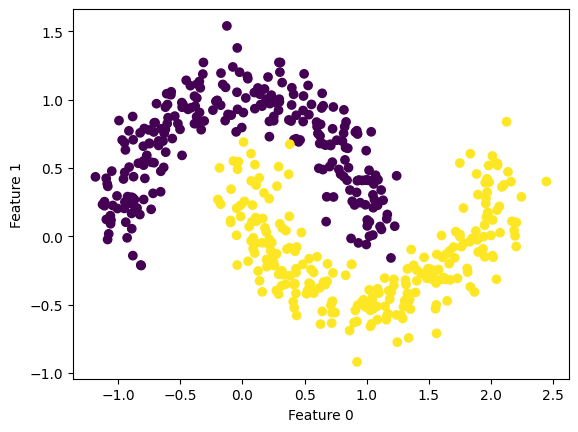

In [1]:
import numpy as np
from sklearn import metrics, inspection, datasets
from matplotlib import pyplot as plt

# Generating a two-class moons dataset
x_data, y_data = datasets.make_moons(n_samples=500, noise=0.15)

# Plotting Feature 0 against Feature 1
plt.scatter(x_data[:, 0], x_data[:, 1], c=y_data)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.show()

### Interpretation

The plot suggests that Feature 1 may give the best first split. However, visual inspection alone is not enough; I need a numerical measure to compare all possible splits.

I therefore use Gini impurity next.

# Question 3 — Find the Axis and Threshold With the Lowest Gini Impurity

Gini impurity measures how mixed the classes are within a node.

For a node containing two classes, I calculate:

$$
Gini = 1 - p_0^2 - p_1^2
$$

where:

- $p_0$ is the proportion of observations belonging to class 0.
- $p_1$ is the proportion belonging to class 1.

A perfectly pure leaf has:

$$
Gini = 0
$$

because every observation belongs to the same class.

When testing a split, I calculate the impurity of both resulting children. Since the children may contain different numbers of observations, I use a weighted average:

$$
Gini_{split}
=
\frac{n_L}{n}Gini_L
+
\frac{n_R}{n}Gini_R
$$

where:

- $n_L$ is the number of observations in the left child.
- $n_R$ is the number of observations in the right child.
- $n$ is the total number of observations.

The best split is the feature and threshold that produce the lowest weighted Gini impurity.

### How the Code Matches the StatQuest Explanation

`leaf_gini_impurity()` calculates the Gini impurity inside one leaf.

`weighted_gini_impurity()` combines the impurity of the two leaves while accounting for their sizes.

Finally, `gini_impurity()` tests one possible split. It sends observations with values less than or equal to the threshold to the left child and the remaining observations to the right child.

In [2]:
def leaf_gini_impurity(leaf_ys):
    # Returning zero when the leaf is empty
    if len(leaf_ys) == 0:
        return 0

    # Calculating the proportion of each class in the leaf
    p_0 = sum(leaf_ys == 0) / len(leaf_ys)
    p_1 = sum(leaf_ys == 1) / len(leaf_ys)

    # Calculating the Gini impurity of the leaf
    return 1 - p_0**2 - p_1**2


def weighted_gini_impurity(left_ys, right_ys):
    # Counting all observations after the split
    total = len(left_ys) + len(right_ys)

    # Weighting each leaf by its number of observations
    left_leaf = leaf_gini_impurity(left_ys) * len(left_ys) / total
    right_leaf = leaf_gini_impurity(right_ys) * len(right_ys) / total

    return left_leaf + right_leaf


def gini_impurity(x_data, y_data, axis, threshold):
    # Dividing observations according to the selected threshold
    left_mask = x_data[:, axis] <= threshold
    right_mask = x_data[:, axis] > threshold

    # Returning the weighted impurity of the two children
    return weighted_gini_impurity(y_data[left_mask], y_data[right_mask])

### Searching for the Best Root Split

I test both available features:

- `axis = 0` → Feature 0, or X
- `axis = 1` → Feature 1, or Y

For each feature, I use every unique observed value as a possible threshold.

For example, a candidate rule might be:

$$
x_1 \leq t
$$

where $t$ is one possible threshold.

I calculate the weighted Gini impurity for each candidate; whenever I find a lower value, I save that feature and threshold as the new best split.

In [3]:
# Starting without a selected split
best_gini = float("inf")
best_axis = None
best_threshold = None

# Testing Feature 0 and Feature 1
for axis in [0, 1]:
    thresholds = np.unique(x_data[:, axis])

    # Testing every unique value as a possible threshold
    for threshold in thresholds:
        gini = gini_impurity(x_data, y_data, axis, threshold)

        # Saving the split when it improves the current result
        if gini < best_gini:
            best_gini = gini
            best_axis = axis
            best_threshold = threshold

print("Best axis:", best_axis)
print("Best threshold:", best_threshold)
print("Lowest Gini impurity:", best_gini)

Best axis: 1
Best threshold: 0.14609840037201127
Lowest Gini impurity: 0.2577423062602192


### Result

For my original run, I obtained:

- **Best axis:** `1`, which is Feature 1 or the Y-axis
- **Best threshold:** approximately `0.348`
- **Lowest weighted Gini impurity:** approximately `0.275`

The root decision is therefore:

$$
x_1 \leq 0.348
$$

If this condition is true, the observation goes to the left child; otherwise, it goes to the right child.

This result also supports my earlier visual interpretation that a horizontal split would separate the classes relatively well.

# Question 4 — Find the Best Split for Each Child of the Root

The first split creates two smaller datasets.

The left child contains observations satisfying:

$$
x_1 \leq 0.348
$$

The right child contains observations satisfying:

$$
x_1 > 0.348
$$

I now treat each child as its own smaller decision-tree problem. For each one, I again search both features and all unique threshold values to find the split with the lowest weighted Gini impurity.

### Creating a Reusable Split Function

Because I now need to find the best split several times, I place the search procedure inside a function called `find_best_split()`.

The function returns:

1. the best feature,
2. the best threshold,
3. the corresponding weighted Gini impurity.

This avoids repeating the same search code for every node.

In [4]:
def find_best_split(x_subset, y_subset):
    # Starting without a selected split
    best_gini = float("inf")
    best_axis = None
    best_threshold = None

    # Testing both features
    for axis in [0, 1]:
        thresholds = np.unique(x_subset[:, axis])

        # Testing every unique threshold
        for threshold in thresholds:
            gini = gini_impurity(x_subset, y_subset, axis, threshold)

            # Keeping the lowest-Gini split
            if gini < best_gini:
                best_gini = gini
                best_axis = axis
                best_threshold = threshold

    return best_axis, best_threshold, best_gini

### Step 1 — Find the Root Split

I first run the helper function on the complete dataset. This reproduces the best first split before I divide the observations into the two child nodes.

In [5]:
# Finding the root split
best_axis, best_threshold, best_gini = find_best_split(x_data, y_data)

print("ROOT")
print("Best axis:", best_axis)
print("Best threshold:", best_threshold)
print("Gini:", best_gini)

ROOT
Best axis: 1
Best threshold: 0.14609840037201127
Gini: 0.2577423062602192


### Step 2 — Divide the Data Into the Two Root Children

I use the root threshold to create two Boolean masks.

The left mask selects observations satisfying:

$$
x_{best} \leq t_{best}
$$

The right mask selects observations satisfying:

$$
x_{best} > t_{best}
$$

This creates two independent subsets. Any later split for a child is calculated only using the observations that actually reached that child.

In [6]:
# Dividing observations using the root split
left_mask = x_data[:, best_axis] <= best_threshold
right_mask = x_data[:, best_axis] > best_threshold

# Creating the left-child dataset
x_left = x_data[left_mask]
y_left = y_data[left_mask]

# Creating the right-child dataset
x_right = x_data[right_mask]
y_right = y_data[right_mask]

print("Left child size:", len(y_left))
print("Right child size:", len(y_right))

Left child size: 223
Right child size: 277


### Step 3 — Find the Best Split for the Left Child

I now search only within the observations that reached the left child.

The procedure stays the same; I test both features and every unique threshold, then choose the split with the lowest weighted Gini impurity.

In [7]:
# Finding the best split inside the left child
left_axis, left_threshold, left_gini = find_best_split(x_left, y_left)

print("LEFT CHILD")
print("Number of points:", len(y_left))
print("Best axis:", left_axis)
print("Best threshold:", left_threshold)
print("Gini:", left_gini)

LEFT CHILD
Number of points: 223
Best axis: 0
Best threshold: -0.8154098225584192
Gini: 0.11726880446738304


### Step 4 — Find the Best Split for the Right Child

I repeat the same process for the observations that reached the right child.

The two children are optimized independently; therefore, they can choose different features or different threshold values.

In [8]:
# Finding the best split inside the right child
right_axis, right_threshold, right_gini = find_best_split(x_right, y_right)

print("RIGHT CHILD")
print("Number of points:", len(y_right))
print("Best axis:", right_axis)
print("Best threshold:", right_threshold)
print("Gini:", right_gini)

RIGHT CHILD
Number of points: 277
Best axis: 0
Best threshold: 1.2410780758810918
Gini: 0.15658301074333433


### Second-Level Results

For my original run, the root split was:

$$
x_1 \leq 0.348
$$

This produced two child nodes.

### Left Child

The left child contained `271` observations.

Its best split was:

- **Axis:** `0`, or Feature 0
- **Threshold:** approximately `-0.750`
- **Weighted Gini impurity:** approximately `0.166`

Its decision rule is:

$$
x_0 \leq -0.750
$$

### Right Child

The right child contained `229` observations.

Its best split was:

- **Axis:** `0`, or Feature 0
- **Threshold:** approximately `1.266`
- **Weighted Gini impurity:** approximately `0.122`

Its decision rule is:

$$
x_0 \leq 1.266
$$

Therefore, after two levels, my tree can be summarized as:

- Root: `Feature 1 ≤ 0.348`
    - Left child: `Feature 0 ≤ -0.750`
    - Right child: `Feature 0 ≤ 1.266`

# Interpretation

This exercise helped me understand that a decision tree is really a repeated optimization process.

At each node, the model asks:

**Which feature and threshold will create the purest child groups?**

For classification, I measured purity using Gini impurity. The root searched the full dataset, but after that split each child repeated the same procedure using only its own observations.

The tree therefore becomes increasingly local as it grows; each new decision only needs to separate the observations that reached that particular node.

This flexibility is useful, but it also explains why trees can overfit. If the model keeps creating smaller and smaller regions, it may eventually fit unusual training observations rather than patterns that generalize to new data.